In [1]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.renderers.default = "png"

In [2]:
load_dotenv("../.env")

True

In [3]:
url = URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT")),
    database=os.getenv("PGDATABASE"),
)

engine = create_engine(url)

In [4]:
scoring_and_segments=pd.read_sql("SELECT * FROM scoring_and_segments", engine)
business_summary=pd.read_sql("SELECT * FROM business_summary", engine)

## Segment size vs revenue share

In [5]:
business_summary_sorted=business_summary.sort_values(by='pct_of_revenue', ascending=False)
business_summary_melt=business_summary_sorted.melt(id_vars=['segment'], value_vars=['pct_of_customers','pct_of_revenue'], var_name='metric', value_name='percentage')

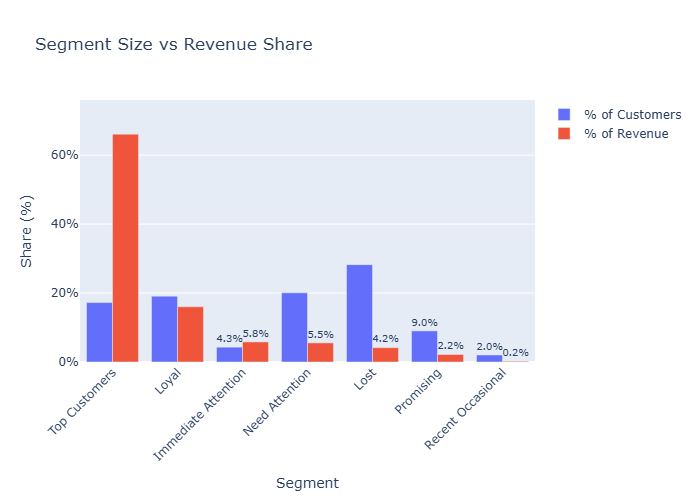

In [6]:
metric_labels = {
    "pct_of_customers": "% of Customers",
    "pct_of_revenue": "% of Revenue",
}
business_summary_melt["metric"] = business_summary_melt["metric"].map(metric_labels)

fig = px.bar(
    business_summary_melt,
    x="segment",
    y="percentage",
    color="metric",
    barmode="group",
    category_orders={"segment": business_summary_sorted["segment"].tolist()},
    labels={
        "segment": "Segment",
        "percentage": "Share (%)",
        "metric": "Metric",
    },
    title="Segment Size vs Revenue Share",
)
max_val = business_summary_melt["percentage"].max()
fig.update_traces(texttemplate="%{y:.1f}%", textposition="outside")
fig.update_layout(
    xaxis_tickangle=-45,
    legend_title_text="",
    yaxis_ticksuffix="%",
    yaxis_range=[0, max_val * 1.15],
    uniformtext_minsize=8,
    uniformtext_mode="hide",
)

fig.show()

## R × FM heatmap

In [7]:
fm_values = list(range(2, 11))  # F+M = 2..10

segment_map = {
    5: ["Recent Occasional"] * 3 + ["Promising"] * 3 + ["Loyal"] + ["Top Customers"] * 2,
    4: ["Promising"] * 3 + ["Loyal"] * 4 + ["Top Customers"] * 2,
    3: ["Need Attention"] * 6 + ["Loyal"] * 3,
    2: ["Lost"] * 3 + ["Need Attention"] * 3 + ["Immediate Attention"] * 3,
    1: ["Lost"] * 6 + ["Immediate Attention"] * 3,
}
assert all(len(v) == len(fm_values) for v in segment_map.values())

df = scoring_and_segments.assign(
    fm_score=lambda d: d["frequency_score"] + d["monetary_score"])

In [8]:
r_values = [1, 2, 3, 4, 5]
counts = (
    df.pivot_table(index="recency_score", columns="fm_score",
                   values="customer_id", aggfunc="count", fill_value=0)
      .reindex(index=r_values, columns=fm_values, fill_value=0)
)
labels = pd.DataFrame(segment_map, index=fm_values).T.reindex(r_values)
cell_text = labels.apply(lambda s: s.str.replace(" ", "<br>")) + "<br><b>" + counts.astype(str) + "</b>"

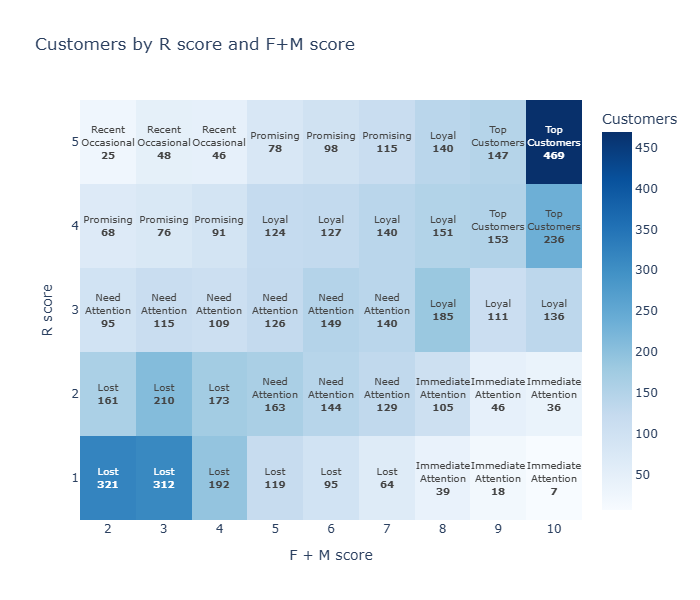

In [9]:
fig = go.Figure(go.Heatmap(
    z=counts.values,
    x=fm_values,
    y=r_values,
    text=cell_text.values,
    texttemplate="%{text}",
    textfont={"size": 10},
    colorscale="Blues",
    colorbar_title="Customers",
    hovertemplate="R=%{y}, F+M=%{x}<br>Customers: %{z}<extra></extra>",
))
fig.update_layout(
    title="Customers by R score and F+M score",
    xaxis=dict(title="F + M score", dtick=1),
    yaxis=dict(title="R score", dtick=1),
    height=600,
)
fig.show()

## RFM profile by segment

In [10]:
profile = (
    scoring_and_segments
    .groupby("segment")[["recency", "frequency", "monetary"]]
    .mean()
    .round(2)
    .sort_values("monetary", ascending=False)
)

profile_norm = (profile - profile.min()) / (profile.max() - profile.min())
# lower Recency is better, so invert it: darker colour = stronger for every metric
profile_norm["recency"] = 1 - profile_norm["recency"]

col_labels = {"recency": "Recency (days)", "frequency": "Frequency (orders)", "monetary": "Monetary"}

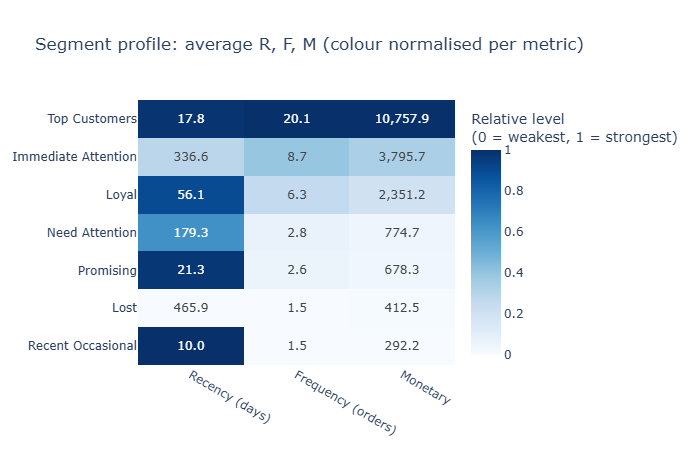

In [11]:
fig = go.Figure(go.Heatmap(
    z=profile_norm.values,
    x=[col_labels[c] for c in profile.columns],
    y=profile.index,
    text=profile.values,
    texttemplate="%{text:,.1f}",
    colorscale="Blues",
    colorbar_title="Relative level<br>(0 = weakest, 1 = strongest)",
    hovertemplate="%{y}<br>%{x}: %{text:,.2f}<extra></extra>",
))
fig.update_layout(
    title="Segment profile: average R, F, M (colour normalised per metric)",
    yaxis=dict(autorange="reversed"),
    height=450,
)
fig.show()